In [4]:
#%pip install seaborn

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt  
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd  
from cartopy.io.shapereader import Reader
import matplotlib.patheffects as pe
import seaborn as sns
from matplotlib.ticker import FuncFormatter, MaxNLocator
from shapely.validation import make_valid  
from shapely.geometry import Point, MultiPolygon  
import pathlib
from tqdm import tqdm
from matplotlib.patches import Patch

os.chdir ('C:\\Users\\hamod4691\\Code\\arctic-benthic-biodiversity\\All data')

# Merge

In [22]:
files = {
    "GBIF": "gbif_final.parquet",
    "OBIS": "obis_final.parquet",
    "CB": "cb_final.parquet",
    "OGSL": "ogsl_final.parquet",
}

dfs = [
    pd.read_parquet(os.path.join("..", folder, fname))
    for folder, fname in files.items()
 ]
all_merged = pd.concat(dfs, ignore_index=True)

# Keep mixed text/number values by normalizing to string
for col in ["sourceID", "eventID"]:
    if col in all_merged.columns:
        all_merged[col] = all_merged[col].apply(
            lambda x: x.decode("utf-8") if isinstance(x, (bytes, bytearray)) else x
        ).astype("string")

# Normalize percentCoverage to string to avoid mixed object types
if "percentCoverage" in all_merged.columns:
    all_merged["percentCoverage"] = all_merged["percentCoverage"].apply(
        lambda x: x.decode("utf-8") if isinstance(x, (bytes, bytearray)) else x
    ).astype("string")

# Clean and coerce percentCoverage to numeric in a new column
if "percentCoverage" in all_merged.columns:
    percent_clean = all_merged["percentCoverage"].astype("string").str.strip()
    percent_clean = percent_clean.str.replace("%", "", regex=False)
    percent_clean = percent_clean.str.replace(",", "", regex=False)
    all_merged["percentCoverage_num"] = pd.to_numeric(percent_clean, errors="coerce")

total_records = len(all_merged)
all_merged.to_parquet("all_merged.parquet", index=False)

total_records

3614601

# Visualize stations

In [23]:
stations = pd.read_parquet("all_merged.parquet")

cols = [
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "datasetKey",
    "datasetTitle",
    "sourceDatabase",
    "year",
    "gebcoDepth",
]
all_stations = stations[cols].drop_duplicates()

total_stations = len(all_stations)
all_stations.to_parquet("all_stations.parquet", index=False)

all_stations

,decimalLatitudeStart,decimalLongitudeStart,datasetKey,datasetTitle,sourceDatabase,year,gebcoDepth
0,81.01390,8.00940,005eb8d8-ed94-41be-89cf-e3115a9058e4,NaN,GBIF,1980.0,-838.0
1,81.83330,8.56670,005eb8d8-ed94-41be-89cf-e3115a9058e4,NaN,GBIF,1980.0,-775.0
2,76.40000,30.00000,005eb8d8-ed94-41be-89cf-e3115a9058e4,NaN,GBIF,1991.0,-295.0
5,60.06780,168.74000,005eb8d8-ed94-41be-89cf-e3115a9058e4,NaN,GBIF,NaN,-130.0
6,60.83530,174.25190,005eb8d8-ed94-41be-89cf-e3115a9058e4,NaN,GBIF,1996.0,-568.0
...,...,...,...,...,...,...,...
3614391,68.49128,-100.65000,amd2018,NaN,OGSL,NaN,-12.0
3614463,68.30935,-100.79838,amd2018,NaN,OGSL,NaN,-57.0
3614506,68.32972,-102.94163,amd2018,NaN,OGSL,NaN,-44.0
3614535,68.47864,-103.43332,amd2018,NaN,OGSL,NaN,-62.0


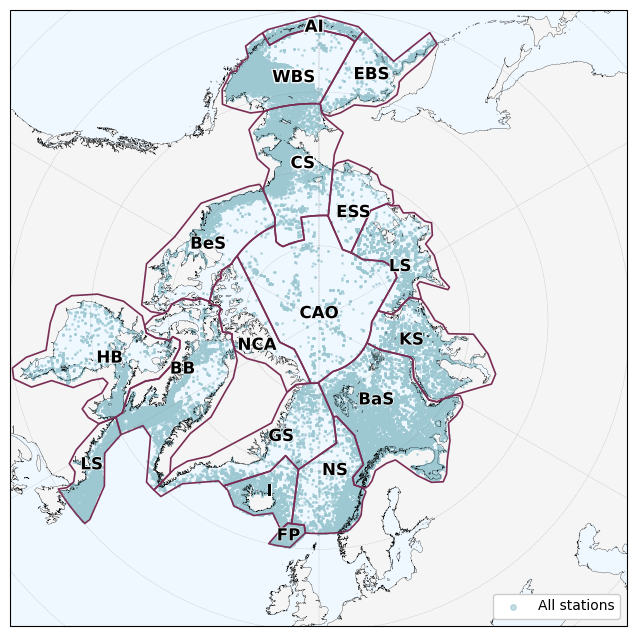

In [ ]:
# Ensure shapefile can be read even if .shx is missing
os.environ['SHAPE_RESTORE_SHX'] = 'YES'

# Load the data from device_water.xlsx
FILEPATH = 'all_stations.parquet'
df_station = pd.read_parquet(FILEPATH)

# Use LatStart and LonStart for coordinates
lat = df_station['decimalLatitudeStart'].copy()
lon = df_station['decimalLongitudeStart'].copy()

# Create coordinates dataframe
coords = pd.DataFrame({
    'lat': pd.to_numeric(lat, errors='coerce'),
    'lon': pd.to_numeric(lon, errors='coerce')
})
coords = coords.dropna()

# Filter to plausible lat/lon ranges
coords = coords[(coords['lat'] >= -90) & (coords['lat'] <= 90) &
                (coords['lon'] >= -180) & (coords['lon'] <= 180)]


# Create the plot with smaller figure size
plt.figure(figsize=(8, 8))
proj = ccrs.NorthPolarStereo()
ax = plt.axes(projection=proj)
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.coastlines(resolution='10m', linewidth=0.2, color='black')
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')

# Add shapefile lines (EPSG:4326, same as stations)
shape_reader = Reader('../LME_boundaries_2014/lme_2013_wgs.shp')
line_feature = cfeature.ShapelyFeature(
    list(shape_reader.geometries()),
    ccrs.PlateCarree(),
    edgecolor='#792D54',
    facecolor='none'
)
ax.add_feature(line_feature, linewidth=1.2)

# Read the shapefile with attributes so we can access names
gdf_lme = gpd.read_file('../LME_boundaries_2014/lme_2013_wgs.shp')

# Ensure coordinates for labeling are in EPSG:4326 (PlateCarree)
gdf_lme_pc = gdf_lme.to_crs(epsg=4326)

# Step 1: Reproject to a projected CRS (e.g., EPSG:3395 for World Mercator)
gdf_lme_projected = gdf_lme.to_crs(epsg=3395)
# Step 2: Calculate centroids in the projected CRS
gdf_lme_projected['centroid'] = gdf_lme_projected.geometry.centroid
# Step 3: Reproject centroids back to the original geographic CRS (EPSG:4326)
gdf_lme_pc['centroid'] = gdf_lme_projected['centroid'].to_crs(epsg=4326)
# Step 4: Extract longitude and latitude for labeling
gdf_lme_pc['lon'] = gdf_lme_pc['centroid'].x  # Extract longitude
gdf_lme_pc['lat'] = gdf_lme_pc['centroid'].y  # Extract latitude


# Step 5: Add labels using the LME field
for _, row in gdf_lme_pc.iterrows():
    if row['LME'] in ['Central Arctic LME', 'Chukchi Sea LME', 'West Bering Sea LME', 'Alutian Islands LME']:
        # Skip these labels in the main loop
        continue
# Handle specific cases for Barents Sea and Beaufort Sea
    if row['LME'] == 'Barents Sea LME':
        short_label = 'BaS'  # Unique abbreviation for Barents Sea
    elif row['LME'] == 'Beaufort Sea LME':
        short_label = 'BeS'  # Unique abbreviation for Beaufort Sea
    else:
        words = row['LME'].split()  # Split the name into words
        short_label = ''.join([word[0] for word in words[:-1]])  # Take the first letter of each word except the last one
    # Add the label to the map
    ax.text(
        row['lon'],
        row['lat'],
        short_label,  # Use the shortened label
        transform=ccrs.PlateCarree(),
        fontsize=12,
        fontweight='bold',  # Make the text bold
        color='black',
        ha='center',
        va='center',
        path_effects=[pe.withStroke(linewidth=1, foreground='white')]
    )

# Step 7: Manual adjustment for problematic labels
for _, row in gdf_lme_pc.iterrows():
    if row['LME'] == 'Central Arctic LME':
        ax.text(
            -179, 89,  # Replace with correct longitude and latitude
            'CAO',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=1, foreground='white')]
        )
    elif row['LME'] == 'Chukchi Sea LME':
        ax.text(
            -174, 69,  # Replace with correct longitude and latitude
            'CS',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
    elif row['LME'] == 'West Bering Sea LME':
        ax.text(
            -174, 58,  # Replace with correct longitude and latitude
            'WBS',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
    elif row['LME'] == 'Alutian Islands LME':
        ax.text(
            -179, 52,  # Replace with correct longitude and latitude
            'AI',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )

# Plot the station points
ax.scatter(coords['lon'].values, coords['lat'].values,
           s=1, color='#9DC8D2', alpha=0.6, transform=ccrs.PlateCarree(), label='All stations')


# Add a legend with a custom markerscale
plt.legend(loc='lower right', markerscale=4, fontsize=10, facecolor='white', framealpha=1)

plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# Over time

In [5]:
# Compute number of records per year from all_merged.parquet and save
all_merged = pd.read_parquet("all_merged.parquet")

if "year" not in all_merged.columns:
    raise ValueError("Column 'year' not found in all_merged.parquet")

records_year = (
    all_merged.dropna(subset=["year"])
    .assign(year=pd.to_numeric(all_merged["year"], errors="coerce"))
    .dropna(subset=["year"])
    .groupby("year")
    .size()
    .reset_index(name="RecordCount")
    .sort_values("year")
)

records_year.to_parquet("records_year.parquet", index=False)
records_year

,year,RecordCount
0,1773.0,1
1,1776.0,23
2,1800.0,4
3,1814.0,1
4,1817.0,6
...,...,...
185,2021.0,388471
186,2022.0,212222
187,2023.0,210252
188,2024.0,189775


In [6]:
# Proportion of stations per year with records from a single phylum
all_merged = pd.read_parquet("all_merged.parquet")

required_cols = ["phylum", "year", "decimalLatitudeStart", "decimalLongitudeStart"]
missing = [col for col in required_cols if col not in all_merged.columns]
if missing:
    raise ValueError(f"Missing columns in all_merged.parquet: {missing}")

stations = (
    all_merged[required_cols]
    .dropna(subset=required_cols)
    .assign(year=pd.to_numeric(all_merged["year"], errors="coerce"))
    .dropna(subset=["year"])
    .assign(year=lambda df: df["year"].astype(int))
    .reset_index(drop=True)
 )

# Count unique phyla per station per year
phylum_counts = (
    stations.groupby(["year", "decimalLatitudeStart", "decimalLongitudeStart"])["phylum"]
    .nunique()
    .reset_index(name="phylum_count")
 )

# Aggregate to yearly proportions
single_stats = (
    phylum_counts.assign(is_single=lambda df: df["phylum_count"] == 1)
    .groupby("year")
    .agg(total_stations=("is_single", "size"), single_stations=("is_single", "sum"))
    .reset_index()
 )
single_stats["prop_single_phylum"] = single_stats["single_stations"] / single_stats["total_stations"]

single_stats.to_parquet("single_phylum.parquet", index=False)
single_stats.sort_values("year").head()

,year,total_stations,single_stations,prop_single_phylum
0,1773,1,1,1.0
1,1776,22,22,1.0
2,1800,4,4,1.0
3,1814,1,1,1.0
4,1817,6,6,1.0


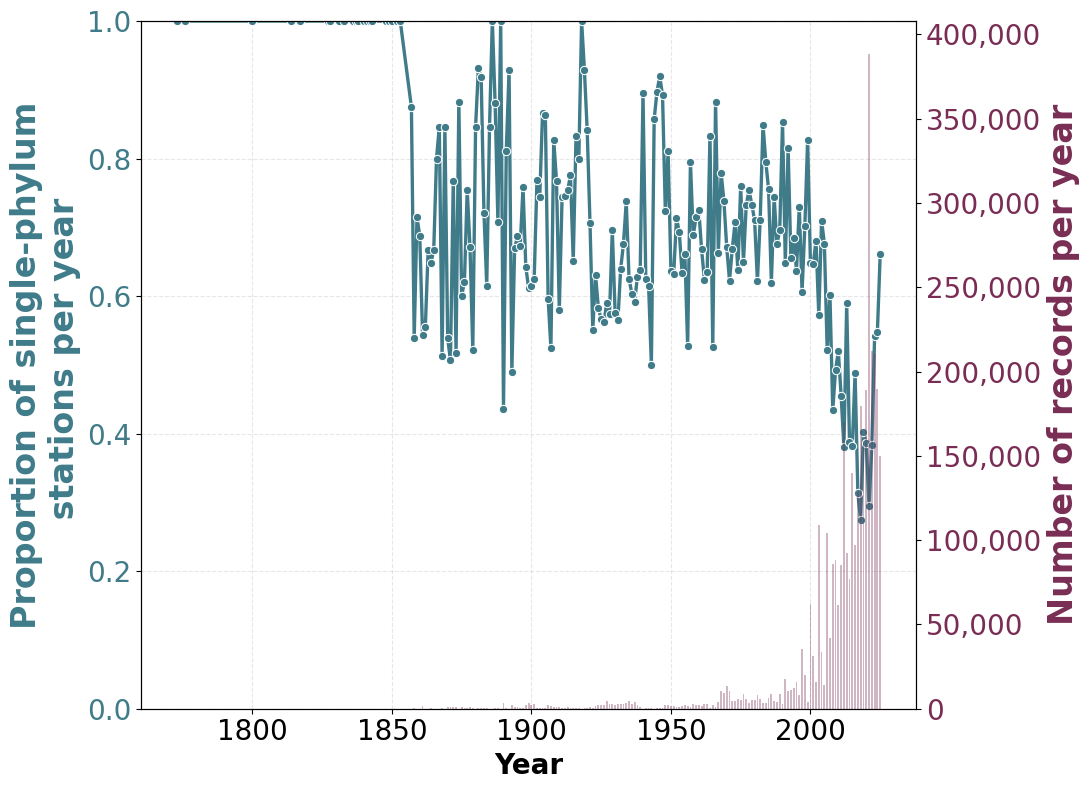

In [23]:
# Load outputs from prior cells
records_year = pd.read_parquet("records_year.parquet")
single_stats = pd.read_parquet("single_phylum.parquet")

# Align for plotting
plot_df_sorted = (
    pd.merge(single_stats, records_year, on="year", how="left")
    .sort_values("year")
 )
plot_df_sorted["RecordCount"] = plot_df_sorted["RecordCount"].fillna(0).astype(int)

# Colors per request
color_prop = '#3F7B89'  # proportion single-phylum (line)
color_recs = '#792D54'  # biota records per year (bars)

plt.figure(figsize=(11, 8))
ax1 = plt.gca()

# Draw bars first on the secondary axis (so the line can be drawn on top)
ax2 = ax1.twinx()
ax2.bar(plot_df_sorted['year'], plot_df_sorted['RecordCount'], color=color_recs, alpha=0.35, width=0.65)
ax2.set_ylabel('Number of records per year', color=color_recs, fontsize=24, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_recs, labelsize=20)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))

# Draw the line on top for visibility
sns.lineplot(data=plot_df_sorted, x='year', y='prop_single_phylum', marker='o', color=color_prop, linewidth=2.4, ax=ax1)
ax1.set_ylabel('Proportion of single-phylum\n stations per year', color=color_prop, fontsize=24, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_prop, labelsize=20)
ax1.set_ylim(0, 1)
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.set_xlabel('Year', fontsize=20, fontweight='bold')
ax1.tick_params(axis="x", labelsize=20)

# Optional: annotate last points for clarity
last_row = plot_df_sorted.dropna(subset=['prop_single_phylum']).iloc[-1]
last_row_rec = plot_df_sorted.dropna(subset=['RecordCount']).iloc[-1]

plt.tight_layout()

# Save outputs
fig_path = 'single_phylum_years.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight', facecolor='None')
plt.show()

# Geomorphological features

Spatial join

In [62]:
# helper: drop rings < 4 points and invalid geometries  
def clean_poly(g):  
    if g is None: return None  
    try: g = make_valid(g)  
    except Exception: return None  
    if g.is_empty or not g.is_valid: return None  
    if g.geom_type == "Polygon":  
        return g if len(g.exterior.coords) >= 4 else None  
    if g.geom_type == "MultiPolygon":  
        parts = [p for p in g.geoms if len(p.exterior.coords) >= 4]  
        if not parts: return None  
        return MultiPolygon(parts) if len(parts) > 1 else parts[0]  
    return None  
  
# 1 ▸ device points  
df  = pd.read_parquet("all_stations.parquet")  
pts = gpd.GeoDataFrame(  
    df,  
    geometry=[Point(xy) for xy in zip(df["decimalLongitudeStart"], df["decimalLatitudeStart"])],  
    crs="EPSG:4326",  
)  
print("Station rows:", len(pts))  
  
# 2 ▸ shapefiles in Geo/  
shp_dir = pathlib.Path("../Geo")  
shps    = sorted(shp_dir.glob("*.shp"))  
print("Found", len(shps), "shapefiles in Geo/")  
  
joined = pts.copy()  
  
for shp in shps:  
    name = shp.stem  
    print("•", name)  
    raw = gpd.read_file(shp)  
    prop_cols = [c for c in raw.columns if c.lower() in ["class", "geomorphic"]]  
  
    # clean layer  
    records = []  
    for _, row in tqdm(raw.iterrows(), total=len(raw), leave=False):  
        geom = clean_poly(row.geometry)  
        if geom is None: continue  
        rec  = {name + "_" + c: row[c] for c in prop_cols}  
        rec["geometry"] = geom  
        records.append(rec)  
  
    if not records:  
        print("  ↳ skipped (no valid polygons)"); continue  
  
    layer = gpd.GeoDataFrame(records, crs=raw.crs).to_crs("EPSG:4326")  
    joined = gpd.sjoin(joined, layer, how="left", predicate="intersects").drop(columns="index_right")  

# Handle duplicate columns by renaming with suffix - after all joins complete
print("Checking for duplicate columns...")
cols = joined.columns.tolist()
new_cols = []
seen = {}
for col in cols:
    if col in seen:
        seen[col] += 1
        new_cols.append(f"{col}_{seen[col]}")
        print(f"  Renamed duplicate '{col}' → '{col}_{seen[col]}'")
    else:
        seen[col] = 0
        new_cols.append(col)
joined.columns = new_cols
  
# 3 ▸ reorder columns  
order = [  
    "Hadal", "Abyss", "Slope", "Shelf", "Abyssal_Classification", "Shelf_Classification",  
    "Plateaus", "Terraces", "Trenches", "Rises", "Fans", "Spreading_ridges", "Ridges",  
    "Troughs", "Rift_valleys", "Shelf_valleys", "Glacial_troughs", "Sills",  
    "Bridges", "Seamounts", "Guyots", "Canyons", "Escarpments", "Basins"  
]  
  
# build full ordered list: point columns first, then *_Class/_Geomorphic in order  
base_cols   = [c for c in joined.columns if c not in joined.geometry.name and not any(c.startswith(x + "_") for x in order)]  
ordered_cols = base_cols.copy()  
added = set(base_cols)  # Track which columns we've already added
for feat in order:  
    for c in joined.columns:
        if c.startswith(feat + "_") and c not in added:
            ordered_cols.append(c)
            added.add(c)
  
joined = joined[ordered_cols + [joined.geometry.name]]  
  
# 4 ▸ save + preview  
out_parquet = "all_stations_geo.parquet"  
joined.drop(columns="geometry").to_parquet(out_parquet, index=False)  
print("✓ saved to", out_parquet)  
print(joined.drop(columns='geometry').head())

Station rows: 163934
Found 24 shapefiles in Geo/
• Abyss


• Abyssal_Classification


• Basins


• Bridges


• Canyons


• Escarpments


... (16 outputs left out)

• Trenches


• Troughs


Checking for duplicate columns...


✓ saved to all_stations_geo.parquet
   decimalLatitudeStart  decimalLongitudeStart  \
0               81.0139                 8.0094   
1               81.8333                 8.5667   
2               76.4000                30.0000   
3               60.0678               168.7400   
4               60.8353               174.2519   

                             datasetKey datasetTitle sourceDatabase    year  \
0  005eb8d8-ed94-41be-89cf-e3115a9058e4          NaN           GBIF  1980.0   
1  005eb8d8-ed94-41be-89cf-e3115a9058e4          NaN           GBIF  1980.0   
2  005eb8d8-ed94-41be-89cf-e3115a9058e4          NaN           GBIF  1991.0   
3  005eb8d8-ed94-41be-89cf-e3115a9058e4          NaN           GBIF     NaN   
4  005eb8d8-ed94-41be-89cf-e3115a9058e4          NaN           GBIF  1996.0   

   gebcoDepth Hadal_Geomorphic Abyss_Geomorphic Slope_Geomorphic  ...  \
0      -838.0              NaN            Abyss              NaN  ...   
1      -775.0              NaN            

In [107]:
# Count stations by Shelf_Classification_Class in all_stations_geo.parquet
df_geo_full = pd.read_parquet("all_stations_geo.parquet")

shelf_counts = (
    df_geo_full["Shelf_Classification_Class"]
    .astype("string")
    .str.lower()
    .str.strip()
    .value_counts()
    .reindex(["high", "medium", "low"])
)

print(shelf_counts)

Shelf_Classification_Class
high      68518
medium    41163
low       19108
Name: count, dtype: int64[pyarrow]


Check all unique combinations

In [63]:
df = pd.read_parquet('all_stations_geo.parquet')
# columns D (index 3) to AD (index 29) inclusive
cols = df.columns[3:32]
subset = df[cols]
print('Selected columns:', list(cols))
# drop duplicates keep unique combos
unique_combos = subset.drop_duplicates().reset_index(drop=True)
print('Unique combinations count:', len(unique_combos))
# save to file for download
outfile = 'unique_geo_combinations.xlsx'
unique_combos.to_excel(outfile, index=False)
print('Saved to', outfile)

Selected columns: ['datasetTitle', 'sourceDatabase', 'year', 'gebcoDepth', 'Hadal_Geomorphic', 'Abyss_Geomorphic', 'Slope_Geomorphic', 'Shelf_Geomorphic', 'Shelf_Classification_Class', 'Shelf_Classification_Geomorphic', 'Shelf_valleys_Geomorphic', 'Abyssal_Classification_Class', 'Abyssal_Classification_Geomorphic', 'Plateaus_Geomorphic', 'Terraces_Geomorphic', 'Trenches_Geomorphic', 'Rises_Geomorphic', 'Fans_Geomorphic', 'Spreading_ridges_Geomorphic', 'Ridges_Geomorphic', 'Troughs_Geomorphic', 'Rift_valleys_Geomorphic', 'Glacial_troughs_Geomorphic', 'Sills_Geomorphic', 'Bridges_Geomorphic', 'Seamounts_Geomorphic', 'Guyots_Geomorphic', 'Canyons_Geomorphic', 'Escarpments_Geomorphic']
Unique combinations count: 78260
Saved to unique_geo_combinations.xlsx


Merge into 7 main categories

In [65]:
input_file = "all_stations_geo.parquet"   
df_geo = pd.read_parquet(input_file)  
  
print("Rows:", len(df_geo))  

# 2. Create the target column and initialize with empty strings  
df_geo["Geo_category"] = ""  

# 3.1  Shelf + high  ➜  Deep shelf  
mask = (  
    df_geo["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df_geo["Shelf_Classification_Class"].str.contains("high", case=False, na=False)  
)  
df_geo.loc[mask, "Geo_category"] = "Deep shelf"  
  
# 3.2  Shelf + medium  ➜  Medium shelf  
mask = (  
    df_geo["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df_geo["Shelf_Classification_Class"].str.contains("medium", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Medium shelf"  
  
# 3.3  Shelf + low  ➜  Shallow shelf  
mask = (  
    df_geo["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df_geo["Shelf_Classification_Class"].str.contains("low", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Shallow shelf"  
  
# 3.4  Slope  ➜  Slope  
mask = (  
    df_geo["Slope_Geomorphic"].str.contains("Slope", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Slope"  
  
# 3.5  Ridges_Geomorphic with “Ridge”  ➜  Ridges  
mask = (  
    df_geo["Ridges_Geomorphic"].str.contains("Ridge", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Ridges"  
  
# 3.6  Spreading_ridges_Geomorphic with “Spreading Ridge”  ➜  Ridges  
mask = (  
    df_geo["Spreading_ridges_Geomorphic"].str.contains("Spreading Ridge", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Ridges"  
  
# 3.7  Rift_valleys_Geomorphic with “Rift Valley”  ➜  Ridges  
mask = (  
    df_geo["Rift_valleys_Geomorphic"].str.contains("Rift Valley", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Ridges"  
  
# 3.8  Abyssal_Classification_Class with “Hills” or “Mountains”  ➜  Abyssal mountains and hills
mask = (  
    df_geo["Abyssal_Classification_Class"].str.contains("Hills|Mountains", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal mountains and hills"  
  
# 3.9  Seamounts_Geomorphic with “Seamount”  ➜  Abyssal mountains and hills 
mask = (  
    df_geo["Seamounts_Geomorphic"].str.contains("Seamount", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal mountains and hills"  
  
# 3.10  Abyssal_Classification_Class with “Plains”  ➜  Abyssal plains and hadal zones
mask = (  
    df_geo["Abyssal_Classification_Class"].str.contains("Plains", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal plains and hadal zones"  
  
# 3.11  Hadal_Geomorphic with “Hadal”  ➜  Abyssal plains and hadal zones  
mask = (  
    df_geo["Hadal_Geomorphic"].str.contains("Hadal", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal plains and hadal zones"  

# Save as excel
output_file = "all_stations_geo_collapsed.parquet"  
df_geo.to_parquet(output_file, index=False)  
  
print("Saved new file:", output_file)  

Rows: 163934
Saved new file: all_stations_geo_collapsed.parquet


Delete unnecessary columns

In [84]:
# Load existing collapsed file 
input_file = 'all_stations_geo_collapsed.parquet'
df_geo = pd.read_parquet(input_file)

# Retain only desired columns (remove sourceDatabase to avoid duplicates)
keep_cols = ['year', 'decimalLatitudeStart', 'decimalLongitudeStart', 'Geo_category']
df_geo = df_geo[keep_cols]

# Deduplicate on (lat, lon, year) - same location should have one Geo_category
df_geo = df_geo.drop_duplicates(subset=['decimalLatitudeStart', 'decimalLongitudeStart', 'year'], keep='first')

# Save to a new file
output_file = 'all_stations_geo_collapsed.parquet'
df_geo.to_parquet(output_file, index=False)

# Show head for confirmation
print(df_geo.head())
print('Saved file as', output_file)
print(f'Total unique station-years: {len(df_geo)}')

     year  decimalLatitudeStart  decimalLongitudeStart  \
0  1980.0               81.0139                 8.0094   
1  1980.0               81.8333                 8.5667   
2  1991.0               76.4000                30.0000   
3     NaN               60.0678               168.7400   
4  1996.0               60.8353               174.2519   

                     Geo_category  
0  Abyssal plains and hadal zones  
1  Abyssal plains and hadal zones  
2                    Medium shelf  
3                      Deep shelf  
4                           Slope  
Saved file as all_stations_geo_collapsed.parquet
Total unique station-years: 134192


How many row lack geo classification? 

In [85]:
# Calculate nr of rows that are lacking a geo category

df = pd.read_parquet('all_stations_geo_collapsed.parquet')

missing_mask = df['Geo_category'].isna() | (df['Geo_category'].str.strip() == '')
missing_count = missing_mask.sum()
print('Missing rows count:', missing_count)

Missing rows count: 6392


Add the Geo_category column to all_merged

In [86]:
# Load the two parquet files
all_merged = pd.read_parquet("all_merged.parquet")
geo_collapsed = pd.read_parquet("all_stations_geo_collapsed.parquet")

# Merge on the combination of decimalLatitudeStart, decimalLongitudeStart, and year
all_merged_geo = all_merged.merge(
    geo_collapsed[['decimalLatitudeStart', 'decimalLongitudeStart', 'year', 'Geo_category']],
    on=['decimalLatitudeStart', 'decimalLongitudeStart', 'year'],
    how='left'
)

# Save the merged dataframe
all_merged_geo.to_parquet("all_merged_geo.parquet", index=False)

print(f"Merged dataframe shape: {all_merged_geo.shape}")
print(f"Original all_merged: {len(all_merged)} records")
print(f"Geo_category column added with {all_merged_geo['Geo_category'].notna().sum()} non-null values")
print(all_merged_geo[['decimalLatitudeStart', 'decimalLongitudeStart', 'year', 'Geo_category']].head(10))

Merged dataframe shape: (3614601, 69)
Original all_merged: 3614601 records
Geo_category column added with 3614601 non-null values
   decimalLatitudeStart  decimalLongitudeStart    year  \
0               81.0139                 8.0094  1980.0   
1               81.8333                 8.5667  1980.0   
2               76.4000                30.0000  1991.0   
3               81.0139                 8.0094  1980.0   
4               81.8333                 8.5667  1980.0   
5               60.0678               168.7400     NaN   
6               60.8353               174.2519  1996.0   
7               81.8333                 8.5667  1980.0   
8               60.1178               169.1347  1988.0   
9               61.7828               178.5872  1994.0   

                     Geo_category  
0  Abyssal plains and hadal zones  
1  Abyssal plains and hadal zones  
2                    Medium shelf  
3  Abyssal plains and hadal zones  
4  Abyssal plains and hadal zones  
5              

In [87]:
# Count records per Geo_category in all_merged_geo.parquet
all_merged_geo = pd.read_parquet("all_merged_geo.parquet")

geo_category_counts = all_merged_geo['Geo_category'].value_counts(dropna=False)

print("Records per Geo_category:")
print(geo_category_counts)
print(f"\nTotal records: {len(all_merged_geo)}")

Records per Geo_category:
Geo_category
Deep shelf                        1819727
Medium shelf                      1141553
Shallow shelf                      246677
Slope                              200347
                                   141253
Abyssal mountains and hills         33178
Ridges                              22812
Abyssal plains and hadal zones       9054
Name: count, dtype: int64

Total records: 3614601


Visualize

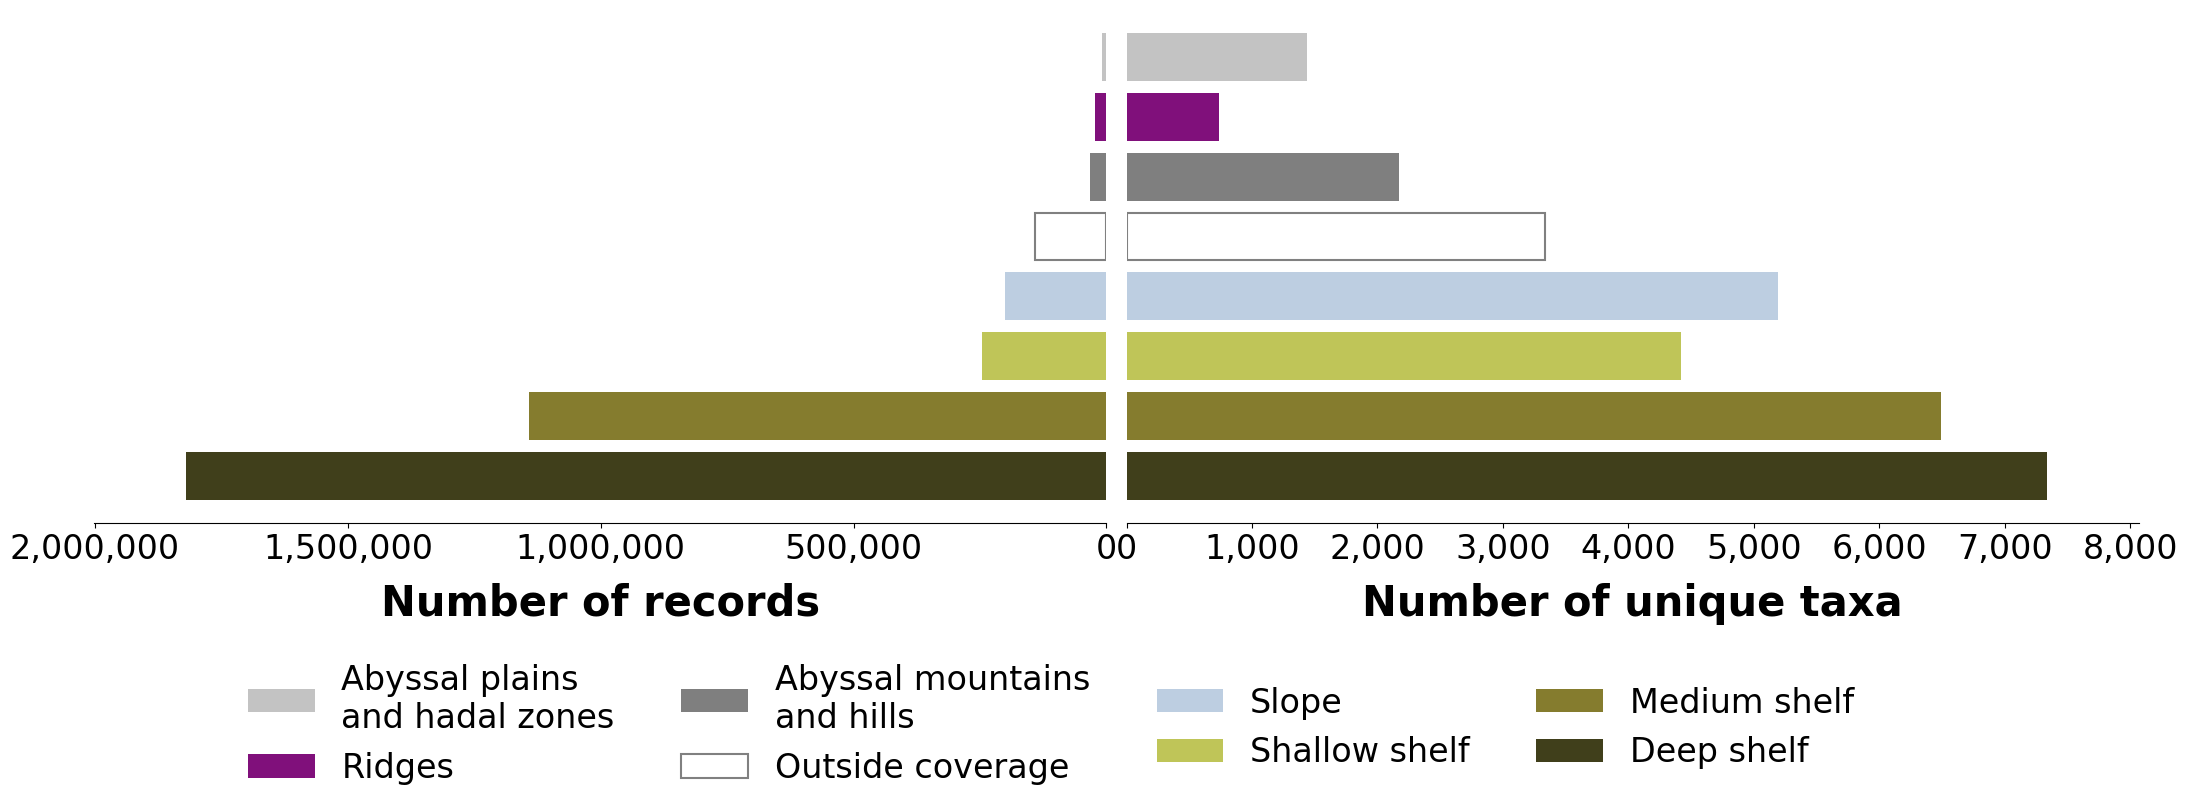

In [24]:
# Load the Excel file
geo_path = 'all_merged_geo.parquet'
biota_geo_df = pd.read_parquet(geo_path)
# Clean column names and handle missing values
biota_geo_df.columns = [c.strip() for c in biota_geo_df.columns]  # Strip whitespace from column names
geo_col = 'Geo_category'
accepted_col = 'aphiaID'
# Ensure required columns exist
if geo_col not in biota_geo_df.columns or accepted_col not in biota_geo_df.columns:
    raise KeyError(f"Required column(s) missing: {geo_col} or {accepted_col}")
# Convert 'AphiaId (Accepted)' to numeric and handle missing values in 'Geo_category'
biota_geo_df[accepted_col] = pd.to_numeric(biota_geo_df[accepted_col], errors='coerce')
# Replace NaN AND empty strings with 'Outside geomorphological categories'
biota_geo_df[geo_col] = biota_geo_df[geo_col].fillna('Outside geomorphological categories')
biota_geo_df[geo_col] = biota_geo_df[geo_col].replace('', 'Outside geomorphological categories')
# Group by 'Geo_category' to calculate metrics
total_records = biota_geo_df.groupby(geo_col, dropna=False).size().reset_index(name='total_records')
unique_taxa = (
    biota_geo_df.dropna(subset=[accepted_col])
                .groupby(geo_col, dropna=False)[accepted_col]
                .nunique()
                .reset_index(name='unique_taxa')
)
# Merge metrics into a single DataFrame
summary_df = pd.merge(total_records, unique_taxa, on=geo_col, how='outer').fillna(0)
summary_df['total_records'] = summary_df['total_records'].astype(int)
summary_df['unique_taxa'] = summary_df['unique_taxa'].astype(int)
# Sort data so that categories with the highest number of records are lowest on the y-axis
summary_df = summary_df.sort_values('total_records', ascending=False)
# Define colors for each category
category_colors = {
    'Abyssal plains and hadal zones': '#C3C3C3',
    'Ridges': '#80107B',
    'Abyssal mountains and hills': '#7F7F7F',
    'Slope': '#BDCEE1',
    'Deep shelf': '#403F1B',
    'Medium shelf': '#857C2E',
    'Shallow shelf': '#BFC558',
    'Outside geomorphological categories': 'white',
}
# Custom legend labels (use \n for line breaks)
legend_label_map = {
    'Abyssal plains and hadal zones': 'Abyssal plains\nand hadal zones',
    'Abyssal mountains and hills': 'Abyssal mountains\nand hills',
    'Outside geomorphological categories': 'Outside coverage',
    # 'Ridges': 'Ridges',
    # 'Slope': 'Slope',
    # 'Deep shelf': 'Deep shelf',
    # 'Medium shelf': 'Medium shelf',
    # 'Shallow shelf': 'Shallow shelf',
}
# Prepare data for plotting
categories = summary_df[geo_col].tolist()
bar_colors = [category_colors.get(cat, 'lightgray') for cat in categories]  # Use .get() with default color
# Define edge colors: black border only for "Outside geomorphological coverage"
bar_edge_colors = ['gray' if cat == 'Outside geomorphological categories' else 'none' for cat in categories]
# Create mirrored bar plot
fig, (ax_left, ax_right) = plt.subplots(
    ncols=2, figsize=(22, 7), gridspec_kw={'width_ratios': [1, 1]}
)
# Plot bars
bars_left = ax_left.barh(
    categories, 
    -summary_df['total_records'], 
    color=bar_colors, 
    edgecolor=bar_edge_colors, 
    linewidth=1.5,  # Set border width
    label='Total records',
)
bars_right = ax_right.barh(
    categories, 
    summary_df['unique_taxa'], 
    color=bar_colors, 
    edgecolor=bar_edge_colors, 
    linewidth=1.5,  # Set border width
    label='Unique taxa',
)
# Format axes
ax_left.set_xlabel('Number of records', fontsize=30, fontweight='bold', labelpad=12)
ax_left.set_xlim(-summary_df['total_records'].max() * 1.1, 0)
ax_left.spines['right'].set_visible(False)
ax_left.spines['top'].set_visible(False)
ax_left.spines['left'].set_visible(False)
ax_left.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
ax_left.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(abs(x)):,}"))
ax_left.tick_params(axis='x', labelsize=24)
ax_right.set_xlabel('Number of unique taxa', fontsize=30, fontweight='bold', labelpad=12)
ax_right.set_xlim(0, summary_df['unique_taxa'].max() * 1.1)
ax_right.spines['left'].set_visible(False)
ax_right.spines['top'].set_visible(False)
ax_right.spines['right'].set_visible(False)
ax_right.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))
ax_right.tick_params(axis='x', labelsize=24)

# Remove y-ticks and labels
ax_left.set_yticks([])
ax_left.set_yticklabels([])
ax_right.set_yticks([])
ax_right.set_yticklabels([])
# Add a legend below the plot
legend_labels = [legend_label_map.get(cat, cat) for cat in categories]
legend_patches = [
    Patch(
        facecolor=category_colors.get(cat, 'lightgray'), 
        edgecolor='gray' if cat == 'Outside geomorphological categories' else 'none', 
        linewidth=1.5
    ) 
    for cat in categories
]
fig.legend(
    legend_patches[::-1], 
    legend_labels[::-1], 
    loc='lower center', 
    bbox_to_anchor=(0.48, -0.25), 
    ncol=4, 
    fontsize=24, 
    frameon=False,
    markerscale=3
)
# Adjust layout and save the plot
plt.tight_layout()
plt.subplots_adjust(top=0.9, wspace=0.02)
plt.savefig('geo_records_taxa.png', dpi=300, bbox_inches='tight', facecolor='None', transparent=True)
plt.show()

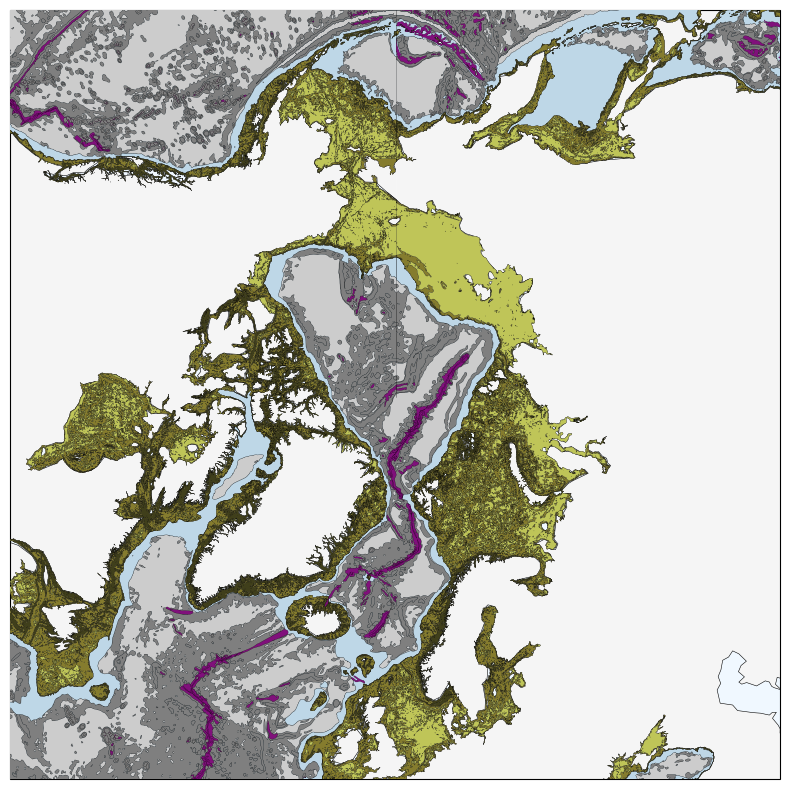

In [25]:
# ------------------------------------------ Map ------------------------------------------------

# Cell 1 — Imports and config

# Folder containing your shapefiles
geo_dir = '../Geo'
# List of shapefile filenames to load from ./Geo (add more as needed)
layer_files = [
    'Hadal.shp',
    'Abyss.shp',
    'Slope.shp',
    'Shelf.shp',
    'Abyssal_Classification.shp',
    'Shelf_Classification.shp',
    'Spreading_ridges.shp',
    'Ridges.shp',
    'Rift_valleys.shp',
    'Seamounts.shp'
]

# Cell 2 — Load shapefiles from ./Geo
layers = {}
for fname in layer_files:
    fpath = os.path.join(geo_dir, fname)
    if os.path.exists(fpath):
        gdf_loaded = gpd.read_file(fpath)
        key_name = os.path.splitext(fname)[0]
        layers[key_name] = gdf_loaded

# Cell 3 — Configure class colors (RGBA) and defaults
abyssal_class_field = 'Class'  # Update this if your column name differs
abyssal_class_colors = {
    'Hills': (0.498, 0.498, 0.498, 1.0),  # fixed
    'Mountains': (0.498, 0.498, 0.498, 1.0),  # fixed
    'Plains': (0.8, 0.8, 0.8, 1.0)   # fixed
}
shelf_class_field = 'Class'  # Update this if your column name differs
shelf_class_colors = {
    'high': (0.251, 0.247, 0.106, 1.0),  # Light blue
    'medium': (0.522, 0.486, 0.180, 1.0),  # Green
    'low': (0.749, 0.773, 0.345, 1.0)   # Orange
}
layer_colors_rgba = {
    'Hadal': (0.8, 0.8, 0.8, 1.0),  # Dark blue, previously (0.129, 0.443, 0.710, 1.0)
    'Abyss': (0.420, 0.682, 0.843, 1.0),  # Light blue
    'Ridges': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Slope': (0.745, 0.843, 0.906, 1.0),  # Purple
    'Shelf': (0.933, 0.953, 1.0, 1.0),  # Purple
    'Spreading_ridges': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Rift_valleys': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Seamounts': (0.498, 0.498, 0.498, 1.0)  # Purple
}
default_color = (0.5, 0.5, 0.5, 0.5)  # Gray with transparency

# Simplify geometries for faster plotting
simp_tol_deg = 0.02
simplified_layers = {}
for lname, gdf in layers.items():
    sgdf = gdf.copy()
    sgdf['geometry'] = sgdf.geometry.simplify(simp_tol_deg, preserve_topology=True)
    simplified_layers[lname] = sgdf

# Cell 4 — Plot preview (rasterized)
fig = plt.figure(figsize=(8, 8))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke', zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue', zorder=0)
ax.coastlines(resolution='110m', linewidth=0.4, color='black', zorder=2)
legend_handles = []
# Define zorder for each layer explicitly
layer_zorder = {
    'Hadal': 3,
    'Abyss': 4,
    'Abyssal_Classification': 5,
    'Shelf_Classification': 8,
    'Slope': 7,
    'Shelf': 6,
    'Spreading_ridges': 9,
    'Ridges': 10,
    'Rift_valleys': 11,
    'Seamounts': 12
}
# Plot layers in the specified order with explicit zorder
for fname in layer_files:
    lname = os.path.splitext(fname)[0]  # Get layer name without extension
    if lname in simplified_layers:
        gdf = simplified_layers[lname]
        rgba = layer_colors_rgba.get(lname, default_color)
        geoms = [geom for geom in gdf.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=rgba,
                edgecolor='k',
                linewidth=0.15,
                alpha=rgba[3],
                zorder=layer_zorder[lname]  # Use explicit zorder
            )
            legend_handles.append(Patch(facecolor=rgba, edgecolor='k', label=lname))
# Plot Abyssal_Classification with class-specific colors
if 'Abyssal_Classification' in simplified_layers:
    gdfc = simplified_layers['Abyssal_Classification']
    for cls_name, cls_rgba in abyssal_class_colors.items():
        subset = gdfc[gdfc[abyssal_class_field].astype(str) == cls_name]
        geoms = [geom for geom in subset.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=cls_rgba,
                edgecolor='k',
                linewidth=0.12,
                alpha=cls_rgba[3],
                zorder=layer_zorder['Abyssal_Classification']  # Explicit zorder for Abyssal_Classification
            )
            legend_handles.append(Patch(facecolor=cls_rgba, edgecolor='k', label='Abyssal ' + cls_name))
# Plot Shelf_Classification with class-specific colors
if 'Shelf_Classification' in simplified_layers:
    gdfc = simplified_layers['Shelf_Classification']
    for cls_name, cls_rgba in shelf_class_colors.items():
        subset = gdfc[gdfc[shelf_class_field].astype(str) == cls_name]
        geoms = [geom for geom in subset.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=cls_rgba,
                edgecolor='k',
                linewidth=0.12,
                alpha=cls_rgba[3],
                zorder=layer_zorder['Shelf_Classification']  # Explicit zorder for Shelf_Classification
            )

plt.tight_layout()
out_path = 'geo_map.png'
plt.savefig(out_path, dpi=300)
plt.show()

In [105]:
# Load the parquet file and save as CSV
df_geo = pd.read_parquet("all_stations_geo_collapsed.parquet")
df_geo.to_csv("all_stations_geo.csv", index=False)
print(f"Saved {len(df_geo)} rows to all_stations_geo.csv")

Saved 134192 rows to all_stations_geo.csv


Biomass, gear, samplingEffort

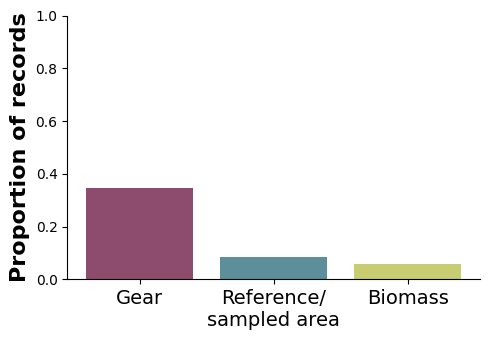

In [128]:
# Proportion of records with gear, samplingEffort, and biomass
all_merged = pd.read_parquet("all_merged.parquet")

cols = ["gear", "samplingEffort", "biomass"]
missing_cols = [c for c in cols if c not in all_merged.columns]
if missing_cols:
    raise KeyError(f"Missing columns in all_merged.parquet: {missing_cols}")

def has_value(s):
    return s.notna() & (s.astype("string").str.strip() != "")

coverage = pd.DataFrame({
    "column": cols,
    "proportion": [has_value(all_merged[c]).mean() for c in cols]
})

# Rename for display
label_map = {
    "gear": "Gear",
    "samplingEffort": "Reference/\nsampled area",
    "biomass": "Biomass"
}
display_labels = [label_map[c] for c in coverage["column"]]

# Use existing palette style
colors = ["#792D54", "#3F7B89", "#BFC558"]

plt.figure(figsize=(5, 3.5))
ax = plt.gca()
bars = ax.bar(display_labels, coverage["proportion"], color=colors, alpha=0.85)

ax.set_ylim(0, 1)
ax.set_ylabel("Proportion of records", fontsize=16, fontweight="bold")
ax.grid(axis="y", linestyle='None', alpha=0.3)

# Remove right and top spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.tick_params(axis='x', labelsize=14)

plt.tight_layout()
plt.savefig("coverage_biomass_etc.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

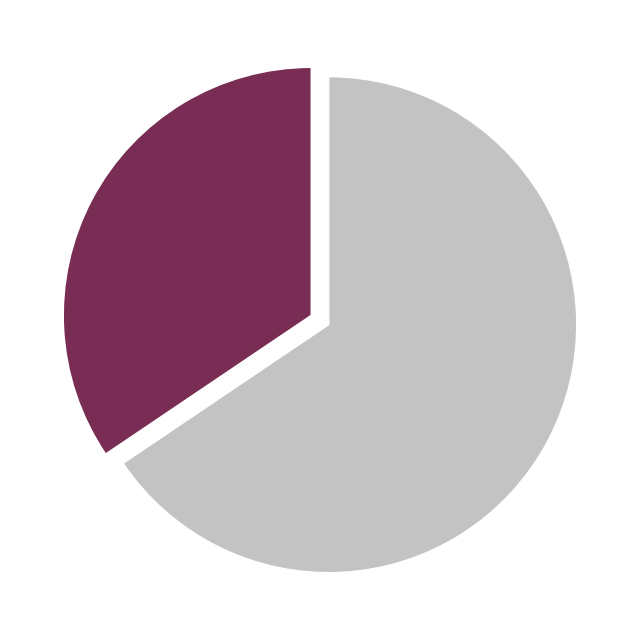

In [141]:
# Pie chart for gear coverage (uses existing all_merged and has_value)
gear_has = has_value(all_merged["gear"])
counts = pd.Series(
    {"With gear": int(gear_has.sum()), "Missing gear": int((~gear_has).sum())}
)

colors = ["#792D54", "#C3C3C3"]
explode = (0.04, 0.04)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
wedges, texts = ax.pie(
    counts.values,
    colors=colors,
    explode=explode,
    startangle=90,
    wedgeprops=dict(edgecolor="white"),
)

ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("gear_coverage_pie.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

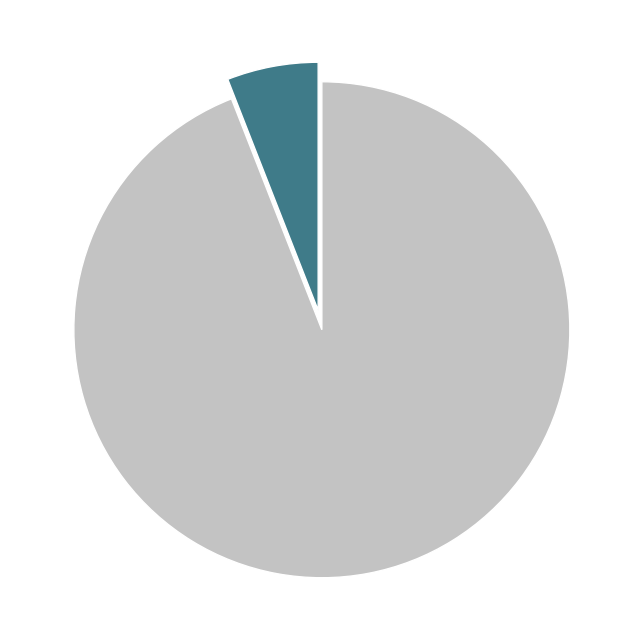

In [142]:
# Pie chart for gear coverage (uses existing all_merged and has_value)
gear_has = has_value(all_merged["biomass"])
counts = pd.Series(
    {"With gear": int(gear_has.sum()), "Missing gear": int((~gear_has).sum())}
)

colors = ["#3F7B89", "#C3C3C3"]
explode = (0.04, 0.04)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
wedges, texts = ax.pie(
    counts.values,
    colors=colors,
    explode=explode,
    startangle=90,
    wedgeprops=dict(edgecolor="white"),
)

ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("biomass_coverage_pie.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

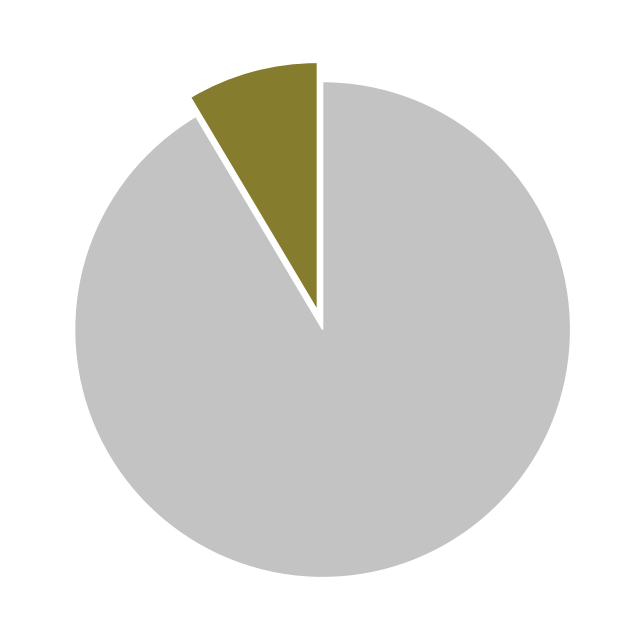

In [143]:
# Pie chart for gear coverage (uses existing all_merged and has_value)
gear_has = has_value(all_merged["samplingEffort"])
counts = pd.Series(
    {"With gear": int(gear_has.sum()), "Missing gear": int((~gear_has).sum())}
)

colors = ["#857C2E", "#C3C3C3"]
explode = (0.04, 0.04)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
wedges, texts = ax.pie(
    counts.values,
    colors=colors,
    explode=explode,
    startangle=90,
    wedgeprops=dict(edgecolor="white"),
)

ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("samplingeffort_coverage_pie.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

# Count the nr of aphiaID

In [127]:

# Count unique aphiaID entries in all_merged.parquet
all_merged = pd.read_parquet("all_merged.parquet")

unique_aphia_count = all_merged['aphiaID'].nunique()

print(f"Number of unique aphiaID entries: {unique_aphia_count}")

Number of unique aphiaID entries: 10354


In [129]:
df_geo = pd.read_parquet(input_file)
unique_station_years = df_geo.drop_duplicates(
    subset=["decimalLatitudeStart", "decimalLongitudeStart", "year"]
)
print("Total unique lat/lon/year combinations:", len(unique_station_years))

Total unique lat/lon/year combinations: 134192
